In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_raw = pd.read_csv("/content/telecom_churn_raw (1).csv")

In [ ]:
(df_raw.dtypes)

,0
customer_id,object
gender,object
senior_citizen,object
partner,object
dependents,object
tenure_months,object
signup_date,object
phone_service,object
multiple_lines,object
internet_service,object


In [ ]:
df_raw.shape

(1300, 23)

In [ ]:
df_raw.columns

Index(['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure_months', 'signup_date', 'phone_service', 'multiple_lines',
       'internet_service', 'online_security', 'tech_support', 'streaming_tv',
       'contract_type', 'paperless_billing', 'payment_method',
       'monthly_charges', 'total_charges', 'avg_monthly_gb', 'support_calls',
       'late_payments', 'customer_satisfaction', 'churn'],
      dtype='object')

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   customer_id            1300 non-null   object
 1   gender                 1272 non-null   object
 2   senior_citizen         1300 non-null   object
 3   partner                1279 non-null   object
 4   dependents             1300 non-null   object
 5   tenure_months          1269 non-null   object
 6   signup_date            1278 non-null   object
 7   phone_service          1300 non-null   object
 8   multiple_lines         1300 non-null   object
 9   internet_service       1273 non-null   object
 10  online_security        1269 non-null   object
 11  tech_support           1273 non-null   object
 12  streaming_tv           1300 non-null   object
 13  contract_type          1279 non-null   object
 14  paperless_billing      1300 non-null   object
 15  payment_method       

In [ ]:
df_raw.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,No
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,Yes
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,No
3,TC-10362,Female,0,Yes,No,NaN,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,No
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,NaN,avg,No


In [ ]:
(df_raw.describe(include='all'))

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
count,1300,1272,1300,1279,1300,1269,1278,1300,1300,1273,...,1279,1300,1260,1266,1273,1237,1255,1258,1228,1291
unique,1251,13,6,14,12,87,233,12,3,11,...,14,12,17,1087,1212,722,14,10,33,14
top,TC-10878,Female,0,Yes,No,12,2024-07-01,Yes,No,Fiber optic,...,Month-to-month,Yes,Electronic check,18.25,?,0.0,1,0,Average,No
freq,2,562,1006,604,825,45,29,1056,575,514,...,645,664,387,25,7,235,359,575,287,815


In [ ]:
("Standard NaN counts per column:")
(df_raw.isnull().sum())

,0
customer_id,0
gender,28
senior_citizen,0
partner,21
dependents,0
tenure_months,31
signup_date,22
phone_service,0
multiple_lines,0
internet_service,27


In [ ]:

# POINT 5: DATA AUDIT REPORT

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from google.colab import files

uploaded = files.upload()
raw_filename = next(iter(uploaded))

df = pd.read_csv(raw_filename)

print("Original dataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

# Check missing values, including blank strings
missing_report = {}

for col in df.columns:
    text_values = df[col].astype("string").str.strip().str.lower()
    missing_count = (
        df[col].isna() |
        text_values.isin(["", "na", "n/a", "null", "none", "nan", "?"])
    ).sum()

    if missing_count > 0:
        missing_report[col] = int(missing_count)

print("\nMissing values:")
print(missing_report if missing_report else "No missing values found.")

# Find exact duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

# Find possible near-duplicates by ignoring case and extra spaces
normalized = df.astype("string").apply(
    lambda col: col.str.strip().str.lower()
)
print("Near-duplicate rows after text normalization:",
      normalized.duplicated().sum())

# Check categorical unique values
print("\nUnique categorical values:")
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(30).to_dict())

# Check numeric-looking columns
numeric_columns = [
    "senior_citizen", "tenure_months", "monthly_charges",
    "total_charges", "avg_monthly_gb", "support_calls",
    "late_payments", "customer_satisfaction"
]

print("\nNumeric conversion problems:")
for col in numeric_columns:
    if col in df.columns:
        cleaned = (
            df[col].astype("string")
            .str.replace(r"[$,]", "", regex=True)
            .str.strip()
        )
        converted = pd.to_numeric(cleaned, errors="coerce")
        print(col, "- values that cannot be converted:",
              int((converted.isna() & df[col].notna()).sum()))

# Save an audit report
audit_lines = [
    f"Dataset shape: {df.shape}",
    f"Exact duplicate rows: {df.duplicated().sum()}",
    f"Near-duplicate rows after case/space normalization: "
    f"{normalized.duplicated().sum()}",
    f"Missing values by column: {missing_report}"
]

with open("data_audit_report.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(audit_lines))

print("\nAudit report saved as data_audit_report.txt")


Saving my_data_cvs.csv to my_data_cvs.csv
Original dataset shape: (0, 1)

Column data types:
Nazish    object
dtype: object

Missing values:
No missing values found.

Exact duplicate rows: 0
Near-duplicate rows after text normalization: 0

Unique categorical values:

Nazish:
{}

Numeric conversion problems:

Audit report saved as data_audit_report.txt


In [ ]:
clean=df_raw.copy()

In [ ]:
clean = df_raw.drop_duplicates(
        subset=["customer_id"], keep="first"
    )

In [ ]:
clean=(df_raw.columns.tolist)

In [ ]:

# POINT 6: DATA CLEANING

clean = df_raw.copy()

# 1. Standardize text: trim spaces and normalize capitalization
for col in clean.select_dtypes(include=["object", "string"]).columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Normalize known text representations of missing values
missing_tokens = ["", "na", "n/a", "null", "none", "nan", "?"]

for col in clean.columns:
    clean[col] = clean[col].apply(
        lambda x: np.nan
        if isinstance(x, str) and x.strip().lower() in missing_tokens
        else x
    )

# 2. Normalize categorical text, while keeping meaningful category labels
for col in clean.select_dtypes(include=["object", "string"]).columns:
    clean[col] = clean[col].apply(
        lambda x: x.lower() if isinstance(x, str) else x
    )

# Standardize Yes/No and gender values
for col in ["partner", "dependents", "phone_service",
            "paperless_billing", "churn"]:
    if col in clean.columns:
        clean[col] = clean[col].replace({
            "yes": "Yes", "no": "No"
        })

if "gender" in clean.columns:
    clean["gender"] = clean["gender"].replace({
        "female": "Female", "male": "Male"
    })

# 3. Convert numeric columns correctly
numeric_columns = [
    "senior_citizen", "tenure_months", "monthly_charges",
    "total_charges", "avg_monthly_gb", "support_calls",
    "late_payments", "customer_satisfaction"
]

for col in numeric_columns:
    if col in clean.columns:
        clean[col] = pd.to_numeric(
            clean[col].astype("string")
            .str.replace(r"[$,]", "", regex=True)
            .str.strip(),
            errors="coerce"
        )

# 4. Parse dates
if "signup_date" in clean.columns:
    clean["signup_date"] = pd.to_datetime(
        clean["signup_date"], errors="coerce"
    )

# 5. Mark impossible values as missing
valid_ranges = {
    "senior_citizen": (0, 1),
    "tenure_months": (0, 120),
    "monthly_charges": (0, 10000),
    "total_charges": (0, 1000000),
    "avg_monthly_gb": (0, 100000),
    "support_calls": (0, 1000),
    "late_payments": (0, 1000),
    "customer_satisfaction": (1, 5)
}

for col, (low, high) in valid_ranges.items():
    if col in clean.columns:
        clean.loc[
            (clean[col] < low) | (clean[col] > high), col
        ] = np.nan

# 6. Remove duplicate rows after text normalization
clean = clean.drop_duplicates()

# 7. A customer ID should identify one customer
if "customer_id" in clean.columns:
    clean = clean.drop_duplicates(
        subset=["customer_id"], keep="first"
    )

# 8. Remove records without a usable target
clean["churn"] = clean["churn"].replace({
    "yes": "Yes", "no": "No"
})
clean = clean[clean["churn"].isin(["Yes", "No"])].copy()

# 9. Fill missing feature values
for col in clean.select_dtypes(include=["object", "string"]).columns:
    if col != "churn":
        clean[col] = clean[col].fillna("Unknown")

for col in numeric_columns:
    if col in clean.columns:
        clean[col] = clean[col].fillna(clean[col].median())

print("Cleaning completed.")
print("Cleaned dataset shape:", clean.shape)
print("\nRemaining missing values:")
print(clean.isna().sum()[clean.isna().sum() > 0])


Cleaning completed.
Cleaned dataset shape: (1192, 23)

Remaining missing values:
signup_date                59
customer_satisfaction    1192
dtype: int64


In [ ]:

# POINT 7: SAVE CLEANED DATA

clean.to_csv("telecom_churn_clean.csv", index=False)

print("Cleaned file saved successfully.")

files.download("telecom_churn_clean.csv")


Cleaned file saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

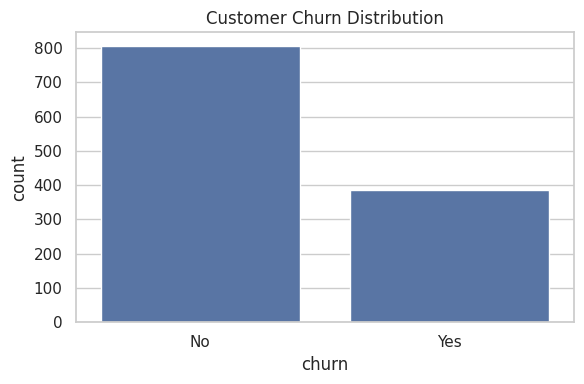

Insight 1: 32.4% of usable customer records are labelled churn.


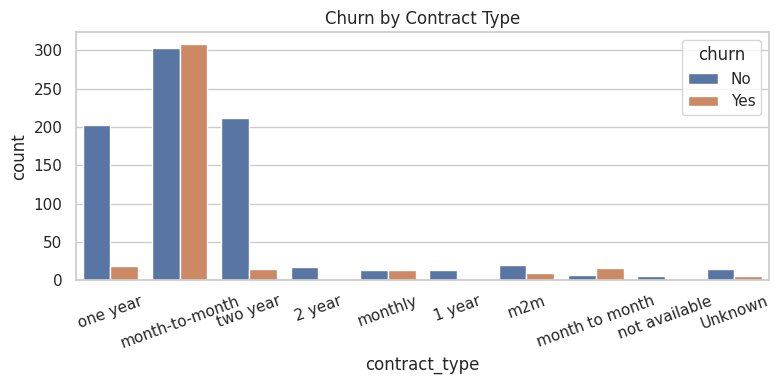

Insight 2: Compare churn counts across contract types to identify higher-churn groups.


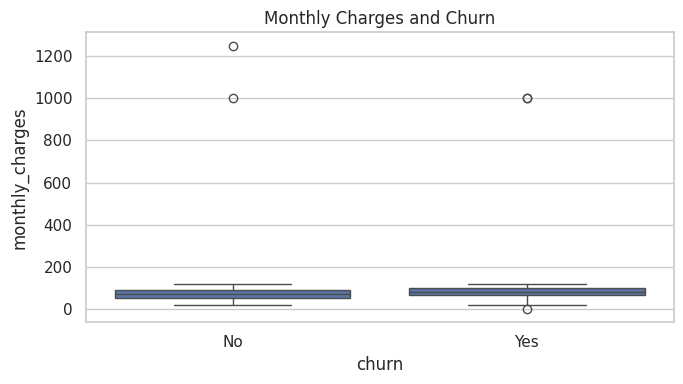

Insight 3: Compare the median and spread of monthly charges for churned and retained customers.


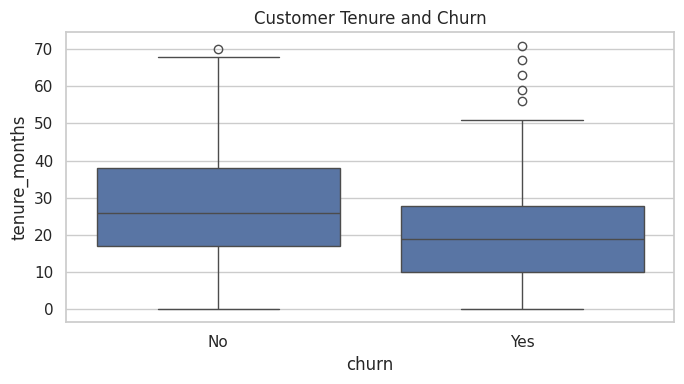

Insight 4: Compare tenure distributions to see whether churned customers tend to have shorter tenure.


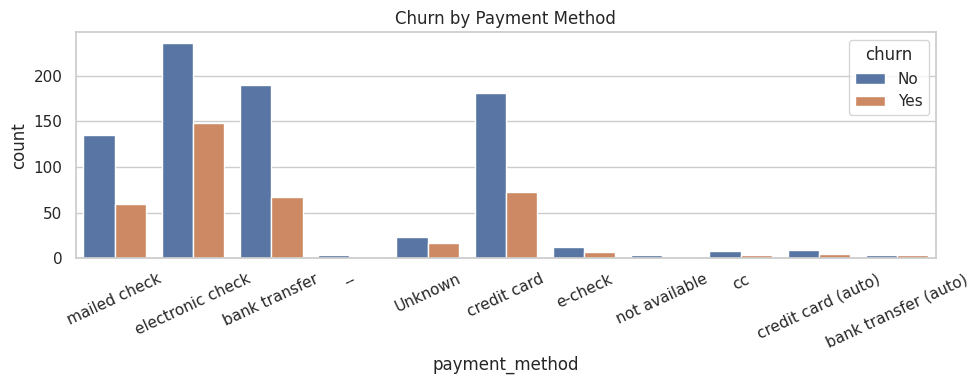

Insight 5: Compare churn counts across payment methods to identify differences between groups.


In [ ]:

# POINT 8: FIVE VISUALIZATIONS

sns.set_theme(style="whitegrid")

# Chart 1: Churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=clean, x="churn")
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.savefig("chart1_churn_distribution.png", dpi=150)
plt.show()

churn_rate = (clean["churn"] == "Yes").mean() * 100
print(f"Insight 1: {churn_rate:.1f}% of usable customer records are labelled churn.")

# Chart 2: Churn by contract type
plt.figure(figsize=(8, 4))
sns.countplot(data=clean, x="contract_type", hue="churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("chart2_contract_churn.png", dpi=150)
plt.show()
print("Insight 2: Compare churn counts across contract types to identify higher-churn groups.")

# Chart 3: Monthly charges by churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean, x="churn", y="monthly_charges")
plt.title("Monthly Charges and Churn")
plt.tight_layout()
plt.savefig("chart3_monthly_charges.png", dpi=150)
plt.show()
print("Insight 3: Compare the median and spread of monthly charges for churned and retained customers.")

# Chart 4: Tenure by churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean, x="churn", y="tenure_months")
plt.title("Customer Tenure and Churn")
plt.tight_layout()
plt.savefig("chart4_tenure_churn.png", dpi=150)
plt.show()
print("Insight 4: Compare tenure distributions to see whether churned customers tend to have shorter tenure.")

# Chart 5: Churn by payment method
plt.figure(figsize=(10, 4))
sns.countplot(data=clean, x="payment_method", hue="churn")
plt.title("Churn by Payment Method")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("chart5_payment_churn.png", dpi=150)
plt.show()
print("Insight 5: Compare churn counts across payment methods to identify differences between groups.")


In [ ]:

# POINT 9: FEATURE ENGINEERING

def tenure_category(months):
    if months < 12:
        return "New"
    elif months < 48:
        return "Established"
    else:
        return "Loyal"

clean["tenure_group"] = clean["tenure_months"].apply(
    tenure_category
)

clean["charges_per_tenure"] = (
    clean["total_charges"] /
    clean["tenure_months"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan)

clean["charges_per_tenure"] = clean["charges_per_tenure"].fillna(
    clean["monthly_charges"]
)

print(clean[[
    "tenure_months", "tenure_group",
    "total_charges", "charges_per_tenure"
]].head())

clean.to_csv("telecom_churn_clean.csv", index=False)


   tenure_months tenure_group  total_charges  charges_per_tenure
0             41  Established         3869.1           94.368293
1             19  Established        1230.23           64.748947
2             64        Loyal        2428.58           37.946562
3             25  Established        3497.22            139.8888
4             24  Established         1710.9             71.2875


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: XGBoost

POINT 12: BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.757,0.596,0.766,0.670
1,Decision Tree,0.657,0.464,0.416,0.438
2,Random Forest,0.753,0.705,0.403,0.512
3,XGBoost,0.732,0.618,0.442,0.515



Best Random Forest parameters:
{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best XGBoost parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}


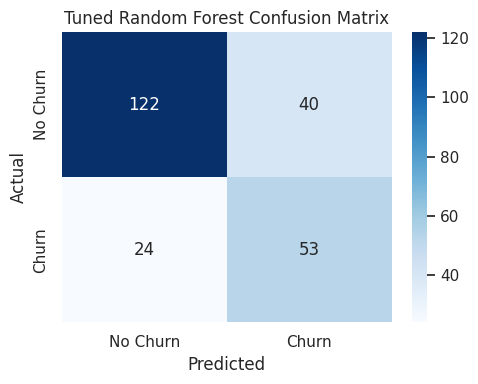


 Tuned Random Forest
              precision    recall  f1-score   support

    No Churn       0.84      0.75      0.79       162
       Churn       0.57      0.69      0.62        77

    accuracy                           0.73       239
   macro avg       0.70      0.72      0.71       239
weighted avg       0.75      0.73      0.74       239



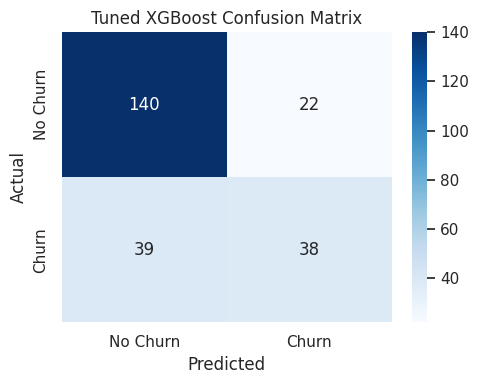


 Tuned XGBoost
              precision    recall  f1-score   support

    No Churn       0.78      0.86      0.82       162
       Churn       0.63      0.49      0.55        77

    accuracy                           0.74       239
   macro avg       0.71      0.68      0.69       239
weighted avg       0.73      0.74      0.74       239


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.757,0.596,0.766,0.670
1,Tuned Random Forest,0.732,0.570,0.688,0.624
2,Tuned XGBoost,0.745,0.633,0.494,0.555
3,XGBoost,0.732,0.618,0.442,0.515
4,Random Forest,0.753,0.705,0.403,0.512
5,Decision Tree,0.657,0.464,0.416,0.438



Selected model: Logistic Regression
Selection reason: Highest F1 score among the evaluated models.
F1 score balances precision and recall. Review churn recall as well before making business decisions.

Model comparison saved as model_comparison.csv


In [ ]:

# POINTS 10-16: MACHINE LEARNING PIPELINE

!pip -q install xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from xgboost import XGBClassifier

# Load cleaned dataset
data = pd.read_csv("telecom_churn_clean.csv")

# Prepare target and features
y = data["churn"].map({"No": 0, "Yes": 1})

# Do not use customer ID or raw signup date as model features
drop_columns = ["churn", "customer_id", "signup_date"]
X = data.drop(
    columns=[c for c in drop_columns if c in data.columns]
).copy()

# Identify categorical and numeric features
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Split BEFORE fitting the preprocessing transformations
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Four baseline models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced", n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=4,
        learning_rate=0.05, random_state=42,
        eval_metric="logloss", n_jobs=2
    )
}

def make_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

def evaluate_model(name, model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_eval, predictions, zero_division=0
        )
    }

# Train and compare the four baseline models
trained_models = {}
baseline_results = []

for name, algorithm in models.items():
    print("Training:", name)
    pipeline = make_pipeline(algorithm)
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    baseline_results.append(
        evaluate_model(name, pipeline, X_test, y_test)
    )

baseline_table = pd.DataFrame(baseline_results)
print("\nPOINT 12: BASELINE MODEL COMPARISON")
display(baseline_table.round(3))

# POINT 13: Tune Random Forest and XGBoost
rf_pipeline = make_pipeline(
    RandomForestClassifier(
        random_state=42, class_weight="balanced", n_jobs=-1
    )
)

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10],
    "model__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    rf_pipeline, rf_params,
    cv=3, scoring="f1", n_jobs=-1
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

print("\nBest Random Forest parameters:")
print(rf_search.best_params_)

xgb_pipeline = make_pipeline(
    XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=2
    )
)

xgb_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.03, 0.1]
}

xgb_search = GridSearchCV(
    xgb_pipeline, xgb_params,
    cv=3, scoring="f1", n_jobs=1
)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

print("\nBest XGBoost parameters:")
print(xgb_search.best_params_)

# POINT 14: Confusion matrix for each tuned model
tuned_models = {
    "Tuned Random Forest": best_rf,
    "Tuned XGBoost": best_xgb
}

for name, model in tuned_models.items():
    predictions = model.predict(X_test)
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name + " Confusion Matrix")
    plt.tight_layout()
    filename = name.lower().replace(" ", "_") + "_confusion_matrix.png"
    plt.savefig(filename, dpi=150)
    plt.show()

    print("\n", name)
    print(classification_report(
        y_test, predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

# POINTS 15-16: Compare all baseline and tuned models
all_results = baseline_results.copy()

for name, model in tuned_models.items():
    all_results.append(
        evaluate_model(name, model, X_test, y_test)
    )

final_table = pd.DataFrame(all_results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(final_table.round(3))

# Select the model with the highest test F1 score
candidate_models = {
    **trained_models,
    **tuned_models
}

best_name = final_table.loc[0, "Model"]
best_model = candidate_models[best_name]

print("\nSelected model:", best_name)
print("Selection reason: Highest F1 score among the evaluated models.")
print(
    "F1 score balances precision and recall. "
    "Review churn recall as well before making business decisions."
)

final_table.to_csv("model_comparison.csv", index=False)
print("\nModel comparison saved as model_comparison.csv")


### Final Model Selection

Four baseline machine learning models were trained and evaluated: Logistic Regression, Decision Tree, Random Forest, and XGBoost. Random Forest and XGBoost were further tuned using cross-validation. The models were compared using accuracy, precision, recall, and F1-score.

The final model was selected based on its test-set F1-score. Recall was also considered because identifying customers who are likely to churn is important for customer retention. The selected model's actual performance metrics are reported in the model comparison table.

The results indicate how machine learning can help identify customers who may leave a telecom service. Predictions should be treated as decision-support information rather than certain outcomes.

In [ ]:

# POINT 17: SAVE FINAL MODEL WITH PREPROCESSING

import joblib

joblib.dump(best_model, "telecom_churn_model.joblib")

print("Final model saved successfully.")
files.download("telecom_churn_model.joblib")


Final model saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

# POINT 18: INTERACTIVE PREDICTION FORM

!pip -q install gradio

import gradio as gr
import pandas as pd
import numpy as np

# Build form inputs from the same model features
form_inputs = []

for col in X.columns:
    if col in categorical_features:
        choices = sorted(
            X[col].dropna().astype(str).unique().tolist()
        )
        form_inputs.append(
            gr.Dropdown(
                choices=choices,
                value=choices[0] if choices else None,
                label=col
            )
        )
    else:
        default_value = float(X[col].median())
        form_inputs.append(
            gr.Number(value=default_value, label=col)
        )

def predict_churn(*values):
    customer = pd.DataFrame([dict(zip(X.columns, values))])

    # Keep feature order and names consistent with training
    customer = customer[X.columns]

    prediction = int(best_model.predict(customer)[0])
    probabilities = best_model.predict_proba(customer)[0]
    churn_probability = float(probabilities[1]) * 100

    label = "Likely to Churn" if prediction == 1 else "Not Predicted to Churn"

    return (
        f"Prediction: {label}",
        f"Estimated churn probability: {churn_probability:.2f}%"
    )

demo = gr.Interface(
    fn=predict_churn,
    inputs=form_inputs,
    outputs=[
        gr.Textbox(label="Churn Prediction"),
        gr.Textbox(label="Churn Probability")
    ],
    title="Telecom Customer Churn Prediction",
    description=(
        "Enter customer details to estimate churn risk. "
        "This is a model estimate, not a guarantee."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://de94b2b96dbdc38e4f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
